# 03 — TCGA: tumor vs normal e tecido de origem (notebook de testes)

Metilação do DNA em **tecido** (Illumina 450K, *beta values* 0–1 por CpG) de 6 tipos tumorais do TCGA, via UCSC Xena.

- **Etapa 1:** tumor primário vs tecido normal adjacente
- **Etapa 2:** tecido de origem entre os tumores (6 classes)
- **Fluxo hierárquico:** etapa 1 → etapa 2 nos positivos

> Atenção: isto é classificação de **tecido tumoral**, não detecção de câncer em cfDNA plasmático.

In [1]:
import sys, gzip, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/<usuario>/GenomicaComputacional.git"  # TODO
if IN_COLAB and not Path("GenomicaComputacional").exists():
    !git clone -q {REPO_URL}

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents, Path("GenomicaComputacional").resolve()]:
        if (p / "PLANO_EXECUCAO.md").exists():
            return p
    return Path.cwd()

ROOT = find_root()
TCGA, PROC = ROOT / "data" / "raw" / "tcga", ROOT / "data" / "processed"
FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"
for d in (TCGA, PROC, FIG, TAB): d.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score,
                             roc_curve, accuracy_score, precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Download (com cache)

Um arquivo por coorte (~180–800 MB cada). O arquivo PanCan único tem 14 GB e não cabe no Colab gratuito.

In [2]:
XENA = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download"
COORTES = {"COAD": "cólon", "STAD": "estômago", "LUAD": "pulmão", "LIHC": "fígado", "BRCA": "mama", "KIRC": "rim"}

def baixar(url, dest):
    # baixa para .part e só renomeia no fim: se a conexão cair, não fica um arquivo cortado passando por completo
    if not dest.exists():
        print("baixando", dest.name, "...")
        tmp = dest.with_name(dest.name + ".part")
        urllib.request.urlretrieve(url, tmp)
        tmp.rename(dest)
    return dest

probemap_path = baixar(f"{XENA}/probeMap%2FilluminaMethyl450_hg19_GPL16304_TCGAlegacy", TCGA / "probeMap_450k.tsv")
for c in COORTES:
    p = baixar(f"{XENA}/TCGA.{c}.sampleMap%2FHumanMethylation450.gz", TCGA / f"TCGA.{c}.HumanMethylation450.gz")
    print(f"{c}: {p.stat().st_size/1e6:.0f} MB")

COAD: 309 MB
STAD: 360 MB
LUAD: 450 MB
LIHC: 386 MB
BRCA: 783 MB
KIRC: 423 MB


## 2. Seleção de amostras e leitura

Código de amostra TCGA: `TCGA-XX-YYYY-TT`, onde `TCGA-XX-YYYY` identifica o **paciente** e `TT` o tipo (`01` = tumor primário, `11` = normal adjacente).

**Amostragem** (para equilibrar classes e caber na memória):
- todas as amostras normais (`11`);
- os tumores **pareados** desses normais (mesmo paciente);
- tumores aleatórios até completar **150 por coorte**.

Leitura em blocos (`chunksize`) e `float32` para economizar memória; já descartamos CpGs dos cromossomos X/Y e sem posição.

In [3]:
MAX_TUMOR = 150
pm = pd.read_csv(probemap_path, sep="\t", index_col=0)
AUTOSSOMOS = {f"chr{i}" for i in range(1, 23)}
probes_auto = set(pm.index[pm["chrom"].isin(AUTOSSOMOS)])
print(f"CpGs no array: {len(pm)} | autossômicos: {len(probes_auto)}")

def escolher_amostras(cols, rng):
    tipo = {s: s[13:15] for s in cols}
    normais = [s for s in cols if tipo[s] == "11"]
    tumores = [s for s in cols if tipo[s] == "01"]
    pac_normais = {s[:12] for s in normais}
    pareados = [s for s in tumores if s[:12] in pac_normais]
    resto = [s for s in tumores if s[:12] not in pac_normais]
    n_extra = max(0, MAX_TUMOR - len(pareados))
    extra = list(rng.choice(resto, size=min(n_extra, len(resto)), replace=False))
    return normais + pareados + extra

def ler_coorte(c, rng):
    path = TCGA / f"TCGA.{c}.HumanMethylation450.gz"
    with gzip.open(path, "rt") as f:
        cols = f.readline().rstrip("\n").split("\t")[1:]
    sel = escolher_amostras(cols, rng)
    blocos = []
    for chunk in pd.read_csv(path, sep="\t", index_col=0, usecols=["sample"] + sel,
                             dtype={s: np.float32 for s in sel}, chunksize=50_000):
        blocos.append(chunk[chunk.index.isin(probes_auto)])
    return pd.concat(blocos)

CACHE = PROC / "tcga_6coortes_top20k.parquet"
if CACHE.exists():
    X = pd.read_parquet(CACHE)
else:
    rng = np.random.default_rng(RANDOM_STATE)
    mats = {}
    for c in COORTES:
        mats[c] = ler_coorte(c, rng); print(c, mats[c].shape)
    M = pd.concat(mats.values(), axis=1, join="inner").T          # amostras x CpGs
    del mats
    print("matriz completa:", M.shape)
    nan_frac = M.isna().mean()
    print(f"CpGs com algum NaN: {(nan_frac > 0).sum()} | removidos")
    M = M.loc[:, nan_frac == 0]
    # filtro NÃO supervisionado (não usa rótulos): 20 mil CpGs de maior variância
    top = M.var().sort_values(ascending=False).index[:20_000]
    X = M[top].copy(); del M
    X.to_parquet(CACHE)
print("X:", X.shape)

CpGs no array: 395985 | autossômicos: 385809


COAD (385809, 188)


STAD (385809, 152)


LUAD (385809, 182)


LIHC (385809, 200)


BRCA (385809, 248)


KIRC (385809, 320)


matriz completa: (1290, 385809)


CpGs com algum NaN: 49549 | removidos


X: (1290, 20000)


In [4]:
meta = pd.DataFrame(index=X.index)
meta["paciente"] = meta.index.str[:12]
meta["tipo"] = np.where(meta.index.str[13:15] == "11", "normal", "tumor")
# a coorte de origem é recuperada do arquivo onde cada amostra estava
origem = {}
for c in COORTES:
    with gzip.open(TCGA / f"TCGA.{c}.HumanMethylation450.gz", "rt") as f:
        for s in f.readline().rstrip("\n").split("\t")[1:]:
            origem[s] = c
meta["coorte"] = meta.index.map(origem)
meta["tecido"] = meta["coorte"].map(COORTES)
display(pd.crosstab(meta["tecido"], meta["tipo"], margins=True))
print("pacientes únicos:", meta["paciente"].nunique(), "| pacientes com tumor + normal:",
      (meta.groupby("paciente")["tipo"].nunique() == 2).sum())

tipo,normal,tumor,All
tecido,,,
cólon,38,150,188
estômago,2,150,152
fígado,50,150,200
mama,98,150,248
pulmão,32,150,182
rim,160,160,320
All,380,910,1290


pacientes únicos: 919 | pacientes com tumor + normal: 371


## 3. Exploração: PCA

Se a metilação carrega a identidade do tecido, as amostras devem se agrupar por **tecido** e, dentro de cada tecido, separar **tumor** de **normal**.

variância explicada: [0.347 0.116 0.07  0.047 0.031]


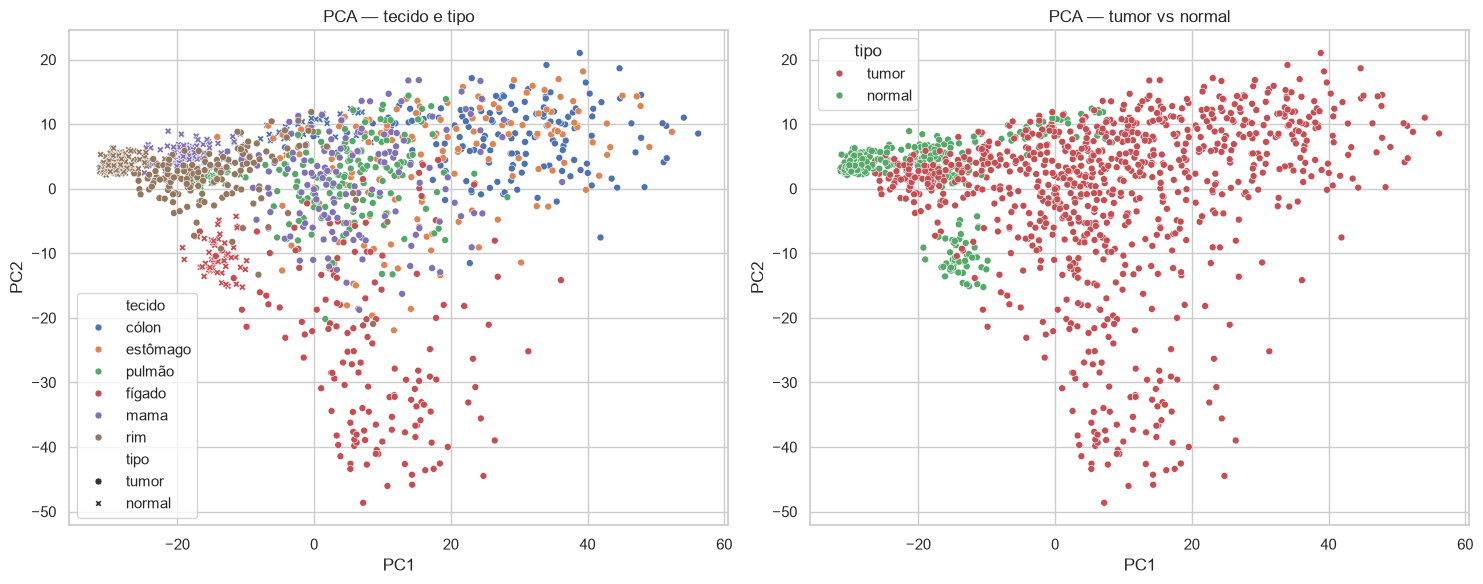

In [5]:
Z = X - X.mean()
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(Z)
pcs = pd.DataFrame(pca.transform(Z)[:, :2], index=X.index, columns=["PC1", "PC2"]).join(meta)
print("variância explicada:", pca.explained_variance_ratio_[:5].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="tecido", style="tipo", s=25, ax=ax[0]).set(title="PCA — tecido e tipo")
sns.scatterplot(data=pcs, x="PC1", y="PC2", hue="tipo", s=25, ax=ax[1], palette={"tumor": "C3", "normal": "C2"}).set(title="PCA — tumor vs normal")
plt.tight_layout(); plt.savefig(FIG / "tcga_pca.png", dpi=150); plt.show()

## 4. Pipeline e validação

- `SelectKBest(f_classif)` (supervisionado) → **dentro** do pipeline.
- `RandomForestClassifier(500 árvores, class_weight="balanced")`.
- **`StratifiedGroupKFold` com grupo = paciente**: tumor e normal do mesmo paciente nunca ficam um no treino e outro no teste. Sem isso, o modelo poderia reconhecer o *indivíduo* (sua metilação constitucional) em vez do tumor.
- Nested CV: externa 5 folds; interna 3 folds para escolher *k*.

In [6]:
def make_pipeline():
    return Pipeline([("selecao", SelectKBest(f_classif)),
                     ("rf", RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

PARAM_GRID = {"selecao__k": [100, 500, 2000]}

def make_search(scoring):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    return GridSearchCV(make_pipeline(), PARAM_GRID, cv=inner, scoring=scoring, n_jobs=1)

def metricas_por_classe(y_true, y_pred, classes):
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    linhas = []
    for i, c in enumerate(classes):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
        prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn)
        linhas.append({"classe": c, "n": cm[i].sum(), "precisao": prec, "sensibilidade": rec,
                       "especificidade": tn / (tn + fp), "f1": 2 * prec * rec / (prec + rec) if prec + rec else 0})
    return pd.DataFrame(linhas).set_index("classe")

def nested_cv(Xt, yt, groups, scoring):
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    classes = sorted(yt.unique())
    pred = pd.Series(index=yt.index, dtype=object); prob = pd.DataFrame(index=yt.index, columns=classes, dtype=float)
    escolhas = []
    for tr, te in outer.split(Xt, yt, groups):
        s = make_search(scoring).fit(Xt.iloc[tr], yt.iloc[tr], groups=groups.iloc[tr])
        pred.iloc[te] = s.predict(Xt.iloc[te]); prob.iloc[te] = s.predict_proba(Xt.iloc[te])
        escolhas.append(s.best_params_["selecao__k"])
    print("k escolhido nos folds externos:", escolhas)
    return pred, prob

## 5. Etapa 1 — Tumor vs normal

k escolhido nos folds externos: [2000, 2000, 2000, 500, 2000]
Acurácia: 0.984 | ROC-AUC: 0.997


,n,precisao,sensibilidade,especificidade,f1
classe,,,,,
normal,380,0.969,0.979,0.987,0.974
tumor,910,0.991,0.987,0.979,0.989


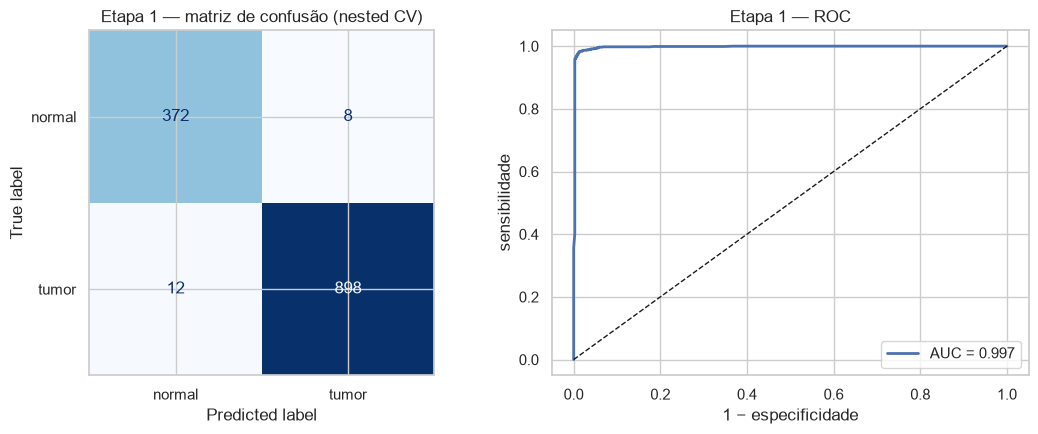

In [7]:
y1 = meta["tipo"]
pred1, prob1 = nested_cv(X, y1, meta["paciente"], "roc_auc")
auc1 = roc_auc_score(y1 == "tumor", prob1["tumor"])
print(f"Acurácia: {accuracy_score(y1, pred1):.3f} | ROC-AUC: {auc1:.3f}")
display(metricas_por_classe(y1, pred1, ["normal", "tumor"]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y1, pred1, labels=["normal", "tumor"]), display_labels=["normal", "tumor"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Etapa 1 — matriz de confusão (nested CV)")
fpr, tpr, _ = roc_curve(y1 == "tumor", prob1["tumor"])
ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {auc1:.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="1 − especificidade", ylabel="sensibilidade", title="Etapa 1 — ROC"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "tcga_etapa1.png", dpi=150); plt.show()

In [8]:
# desempenho da etapa 1 dentro de cada tecido
por_tecido = (pd.DataFrame({"tecido": meta["tecido"], "y": y1, "pred": pred1})
                .groupby("tecido").apply(lambda d: pd.Series({
                    "n_normal": (d.y == "normal").sum(), "n_tumor": (d.y == "tumor").sum(),
                    "sensibilidade": ((d.pred == "tumor") & (d.y == "tumor")).sum() / (d.y == "tumor").sum(),
                    "especificidade": ((d.pred == "normal") & (d.y == "normal")).sum() / max((d.y == "normal").sum(), 1)})))
por_tecido.round(3)

,n_normal,n_tumor,sensibilidade,especificidade
tecido,,,,
cólon,38.0,150.0,1.000,0.921
estômago,2.0,150.0,0.993,0.000
fígado,50.0,150.0,0.967,0.960
mama,98.0,150.0,0.993,0.990
pulmão,32.0,150.0,0.987,1.000
rim,160.0,160.0,0.981,1.000


## 6. Etapa 2 — Tecido de origem (só tumores, 6 classes)

k escolhido nos folds externos: [2000, 2000, 2000, 2000, 500]
Acurácia: 0.980 | F1 macro: 0.980 | ROC-AUC macro (OvR): 0.999


,n,precisao,sensibilidade,especificidade,f1
classe,,,,,
cólon,150,0.979,0.940,0.996,0.959
estômago,150,0.929,0.960,0.986,0.944
fígado,150,1.000,1.000,1.000,1.000
mama,150,0.987,1.000,0.997,0.993
pulmão,150,0.993,0.987,0.999,0.990
rim,160,0.994,0.994,0.999,0.994


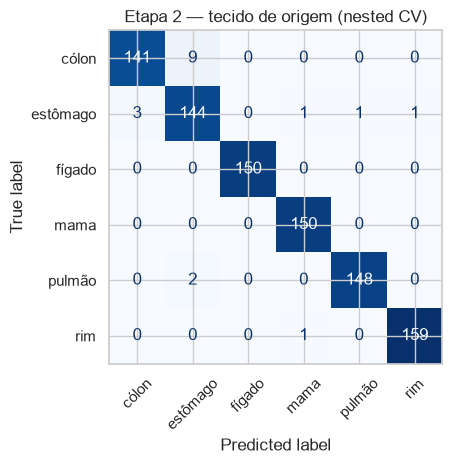

In [9]:
tum = meta.index[meta["tipo"] == "tumor"]
y2 = meta.loc[tum, "tecido"]
pred2, prob2 = nested_cv(X.loc[tum], y2, meta.loc[tum, "paciente"], "f1_macro")
classes2 = sorted(y2.unique())
auc2 = roc_auc_score(y2, prob2[classes2], multi_class="ovr", average="macro")
print(f"Acurácia: {accuracy_score(y2, pred2):.3f} | F1 macro: {f1_score(y2, pred2, average='macro'):.3f} | ROC-AUC macro (OvR): {auc2:.3f}")
display(metricas_por_classe(y2, pred2, classes2).round(3))

cm2 = confusion_matrix(y2, pred2, labels=classes2)
ConfusionMatrixDisplay(cm2, display_labels=classes2).plot(cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Etapa 2 — tecido de origem (nested CV)"); plt.tight_layout(); plt.savefig(FIG / "tcga_etapa2.png", dpi=150); plt.show()

## 7. Fluxo hierárquico (out-of-fold)

Usa as predições fora da amostra das duas etapas. Para normais erroneamente chamados de tumor na etapa 1, a etapa 2 é aplicada com um modelo treinado em todos os tumores.

Acurácia hierárquica (7 classes): 0.971


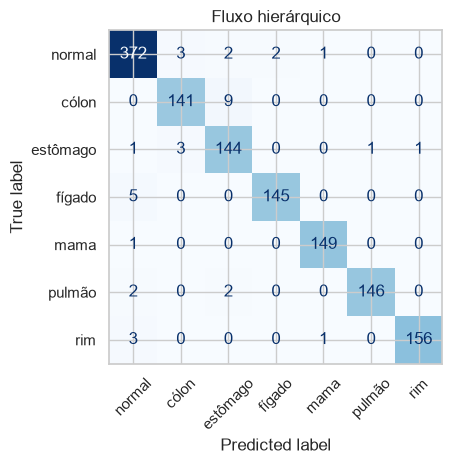

In [10]:
final = pd.Series("normal", index=X.index)
pos = pred1.index[pred1 == "tumor"]
pos_tumor = [s for s in pos if s in pred2.index]
final[pos_tumor] = pred2[pos_tumor]
fp_normais = [s for s in pos if s not in pred2.index]
if fp_normais:
    m2 = make_pipeline().set_params(selecao__k=500).fit(X.loc[tum], y2)
    final[fp_normais] = m2.predict(X.loc[fp_normais])
verdade = np.where(meta["tipo"] == "normal", "normal", meta["tecido"])
ordem = ["normal"] + classes2
print(f"Acurácia hierárquica (7 classes): {accuracy_score(verdade, final):.3f}")
ConfusionMatrixDisplay(confusion_matrix(verdade, final, labels=ordem), display_labels=ordem).plot(cmap="Blues", colorbar=False, xticks_rotation=45)
plt.title("Fluxo hierárquico"); plt.tight_layout(); plt.savefig(FIG / "tcga_hierarquico.png", dpi=150); plt.show()

## 8. CpGs mais importantes

Modelo final ajustado em 75% dos pacientes (split agrupado) e *permutation importance* nos 25% restantes. Os CpGs são anotados com o gene mais próximo (probe map do Xena).

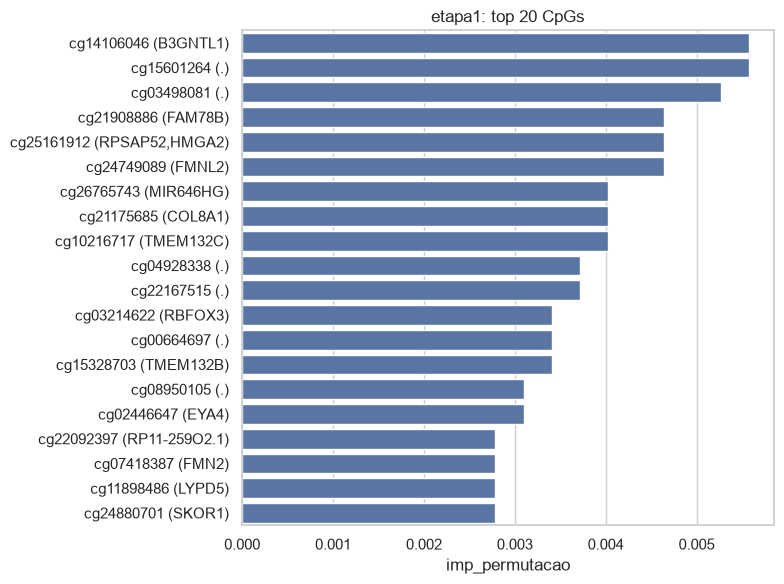

,cpg,imp_permutacao,imp_impureza,gene,chrom,chromStart
478,cg14106046,0.005573,0.023983,B3GNTL1,chr17,81006484
457,cg15601264,0.005573,0.009288,.,chr17,54864696
305,cg03498081,0.005263,0.018443,.,chr16,80061356
474,cg21908886,0.004644,0.007334,FAM78B,chr1,166039443
456,cg25161912,0.004644,0.010530,"RPSAP52,HMGA2",chr12,66220770
497,cg24749089,0.004644,0.024896,FMNL2,chr2,153322822
118,cg26765743,0.004025,0.028844,MIR646HG,chr20,59047487
383,cg21175685,0.004025,0.006244,COL8A1,chr3,99378031
176,cg10216717,0.004025,0.002674,TMEM132C,chr12,128899289
249,cg04928338,0.003715,0.012059,.,chr16,5286491


In [11]:
def importancias(Xt, yt, groups, tag, k=500, top=20):
    tr, te = next(StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE).split(Xt, yt, groups))
    m = make_pipeline().set_params(selecao__k=k).fit(Xt.iloc[tr], yt.iloc[tr])
    nomes = Xt.columns[m.named_steps["selecao"].get_support()]
    Xs = m.named_steps["selecao"].transform(Xt.iloc[te])
    pi = permutation_importance(m.named_steps["rf"], Xs, yt.iloc[te], n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    imp = (pd.DataFrame({"cpg": nomes, "imp_permutacao": pi.importances_mean,
                         "imp_impureza": m.named_steps["rf"].feature_importances_})
             .join(pm[["gene", "chrom", "chromStart"]], on="cpg").sort_values("imp_permutacao", ascending=False))
    imp.to_csv(TAB / f"tcga_importancias_{tag}.csv", index=False)
    t = imp.head(top).assign(rotulo=lambda d: d["cpg"] + " (" + d["gene"].astype(str) + ")")
    plt.figure(figsize=(8, 6)); sns.barplot(data=t, y="rotulo", x="imp_permutacao", color="C0")
    plt.title(f"{tag}: top {top} CpGs"); plt.ylabel(""); plt.tight_layout(); plt.savefig(FIG / f"tcga_importancias_{tag}.png", dpi=150); plt.show()
    return imp

imp1 = importancias(X, y1, meta["paciente"], "etapa1")
imp1.head(15)

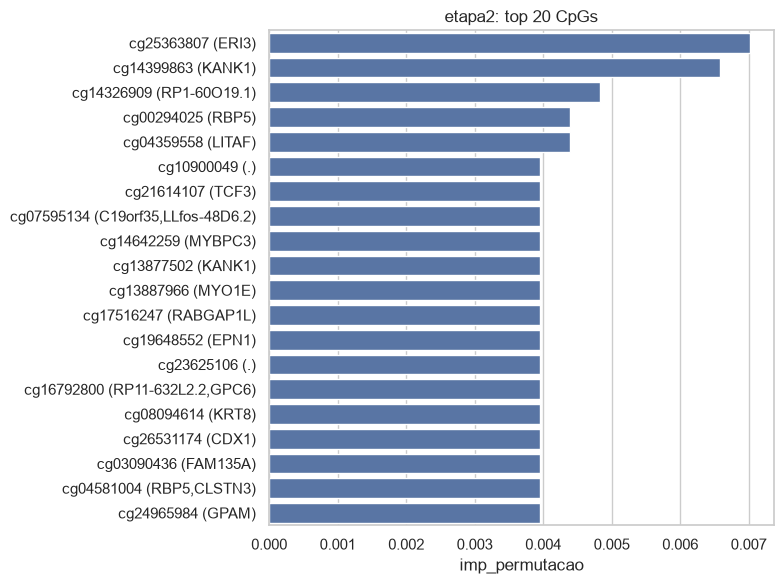

,cpg,imp_permutacao,imp_impureza,gene,chrom,chromStart
22,cg25363807,0.007018,0.008201,ERI3,chr1,44703922
338,cg14399863,0.006579,0.006414,KANK1,chr9,707165
250,cg14326909,0.004825,0.012868,RP1-60O19.1,chr6,107235622
173,cg00294025,0.004386,0.002066,RBP5,chr12,7276359
350,cg04359558,0.004386,0.007685,LITAF,chr16,11648223
25,cg10900049,0.003947,0.001993,.,chr2,8849961
497,cg21614107,0.003947,0.004136,TCF3,chr19,1633072
376,cg07595134,0.003947,0.001556,"C19orf35,LLfos-48D6.2",chr19,2278707
66,cg14642259,0.003947,0.000246,MYBPC3,chr11,47359016
83,cg13877502,0.003947,0.005224,KANK1,chr9,707386


In [12]:
imp2 = importancias(X.loc[tum], y2, meta.loc[tum, "paciente"], "etapa2")
imp2.head(15)

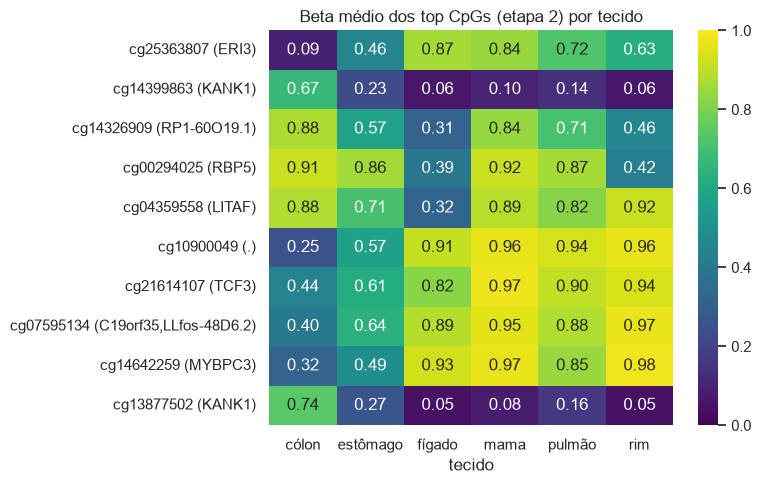

In [13]:
# metilação dos top CpGs da etapa 2 por tecido (média do beta) — ajuda a interpretar
top_cpgs = imp2["cpg"].head(10).tolist()
heat = X.loc[tum, top_cpgs].groupby(y2).mean().T
heat.index = [f"{c} ({pm.loc[c, 'gene']})" for c in heat.index]
plt.figure(figsize=(8, 5)); sns.heatmap(heat, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Beta médio dos top CpGs (etapa 2) por tecido"); plt.tight_layout(); plt.savefig(FIG / "tcga_heatmap_top_etapa2.png", dpi=150); plt.show()